### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DVFM_Y = data.copy()
mask = (DVFM_Y['category']=='vegetables and fruits') & (DVFM_Y['region']=='Yangon')
DVFM_Y = DVFM_Y.loc[mask]
DVFM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
27764,7/15/2021,Yangon,Yangon (East),Zamyinzwel,vegetables and fruits,Tomatoes (local),local,NaN,KG,actual,Retail,MMK,1800.0,1.0112
27770,7/15/2021,Yangon,Yangon (North),Meegwet,vegetables and fruits,Onions (local),local,NaN,KG,actual,Retail,MMK,449.0,0.2522
27771,7/15/2021,Yangon,Yangon (North),Meegwet,vegetables and fruits,Tomatoes (local),local,NaN,KG,actual,Retail,MMK,1350.0,0.7584
27777,7/15/2021,Yangon,Yangon (North),YwarMa,vegetables and fruits,Onions (local),local,NaN,KG,actual,Retail,MMK,449.0,0.2522
27778,7/15/2021,Yangon,Yangon (North),YwarMa,vegetables and fruits,Tomatoes (local),local,NaN,KG,actual,Retail,MMK,2000.0,1.1236


In [13]:
obv_st_date = pd.to_datetime("2021-07-01")
pred_st_date = pd.to_datetime("2021-07-01")

In [14]:
DVFM_Y = DVFM_Y[['date', 'price']]
DVFM_Y['date'] = pd.to_datetime(DVFM_Y['date'])
mask = (DVFM_Y['date']>=obv_st_date) & (DVFM_Y['date']<=obv_end_date)
DVFM_Y = DVFM_Y.loc[mask]
DVFM_Y = DVFM_Y.set_index('date')
DVFM_Y.head()

,price
date,
2021-07-15,1800.0
2021-07-15,449.0
2021-07-15,1350.0
2021-07-15,449.0
2021-07-15,2000.0


In [15]:
DVFM_Y = DVFM_Y.resample('MS').mean()
DVFM_Y.head()

,price
date,
2021-07-01,1209.60000
2021-08-01,NaN
2021-09-01,810.68375
2021-10-01,979.10000
2021-11-01,1507.03900


In [16]:
price = DVFM_Y['price']
date = DVFM_Y.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DVFM_Y = scaler.fit_transform(DVFM_Y)
DVFM_Y = pd.DataFrame(DVFM_Y)
DVFM_Y.head()

,0
0,0.308913
1,NaN
2,0.000000
3,0.130418
4,0.539244


In [19]:
DVFM_Y['date']=date
DVFM_Y = DVFM_Y.set_index('date')
DVFM_Y.columns=['price']
DVFM_Y.head()

,price
date,
2021-07-01,0.308913
2021-08-01,NaN
2021-09-01,0.000000
2021-10-01,0.130418
2021-11-01,0.539244


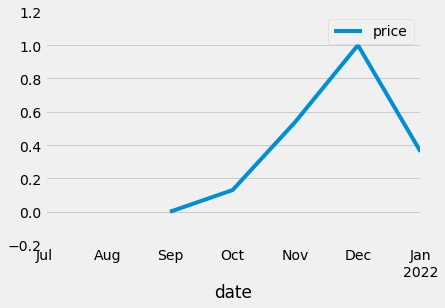

In [20]:
DVFM_Y.plot(grid=True)
plt.show()

It has some missing data.

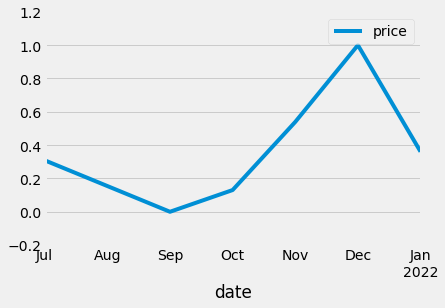

In [21]:
DVFM_Y = DVFM_Y.interpolate(method="linear")
DVFM_Y.plot(grid=True)
plt.show()

It will hard to predict because of not enough records.

In [22]:
pred_end_date = pd.to_datetime("2022-09-01")

##### Checking Random Walk

In [24]:
RW_DVFM_Y= adfuller(DVFM_Y)
RW_DVFM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

4.655174526304309e-07

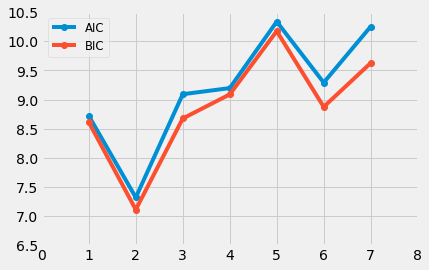

In [25]:
AIC, BIC = AIC_BIC_withOrderRange(DVFM_Y, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [26]:
AIC, BIC

(array([11.34447281,  8.71845058,  7.32019458,  9.09078978,  9.19558044,
        10.33466982,  9.28996271, 10.25020426]),
 array([11.29038296,  8.61027088,  7.11195405,  8.67430871,  9.08740073,
        10.17240027,  8.87348165,  9.62548267]))

We will run again 2:(0,1,0)

In [27]:
mod_orders = [
    (0,1,0),
]

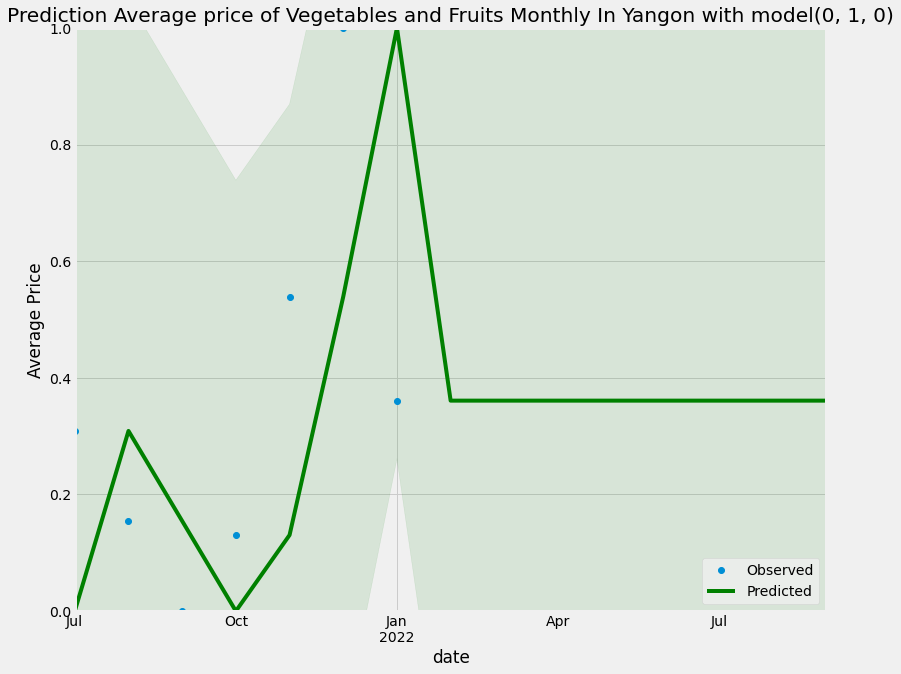

In [28]:
DVFM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DVFM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Vegetables and Fruits Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DVFM_Y_models.append(model)

Now we choose (0,1,0)

In [29]:
DVFM_Y_model = DVFM_Y_models[0]

In [30]:
DVFM_Y_pred_normalized = DVFM_Y_model.predict(pred_st_date, pred_end_date)
DVFM_Y_pred_normalized

2021-07-01    0.000000e+00
2021-08-01    3.089129e-01
2021-09-01    1.544564e-01
2021-10-01   -3.398060e-12
2021-11-01    1.304182e-01
2021-12-01    5.392438e-01
2022-01-01    1.000000e+00
2022-02-01    3.608738e-01
2022-03-01    3.608738e-01
2022-04-01    3.608738e-01
2022-05-01    3.608738e-01
2022-06-01    3.608738e-01
2022-07-01    3.608738e-01
2022-08-01    3.608738e-01
2022-09-01    3.608738e-01
Freq: MS, Name: predicted_mean, dtype: float64

We need to un-normalized the predicted value to get actual price

In [31]:
pred_date = DVFM_Y_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2021-07-01', '2021-08-01', '2021-09-01', '2021-10-01',
               '2021-11-01', '2021-12-01', '2022-01-01', '2022-02-01',
               '2022-03-01', '2022-04-01', '2022-05-01', '2022-06-01',
               '2022-07-01', '2022-08-01'],
              dtype='datetime64[ns]', freq='MS')

In [32]:
DVFM_Y_pred_normalized_df = pd.DataFrame(DVFM_Y_pred_normalized)
DVFM_Y_pred_normalized_df = DVFM_Y_pred_normalized_df[:-1] # the last index doesn't need
DVFM_Y_pred_normalized_df

,predicted_mean
2021-07-01,0.000000e+00
2021-08-01,3.089129e-01
2021-09-01,1.544564e-01
2021-10-01,-3.398060e-12
2021-11-01,1.304182e-01
2021-12-01,5.392438e-01
2022-01-01,1.000000e+00
2022-02-01,3.608738e-01
2022-03-01,3.608738e-01
2022-04-01,3.608738e-01


##### Un-normalization data

In [33]:
DVFM_Y_pred_act = scaler.inverse_transform(DVFM_Y_pred_normalized_df)
DVFM_Y_pred_act_df = pd.DataFrame(DVFM_Y_pred_act)
DVFM_Y_pred_act_df['date'] = pred_date
DVFM_Y_pred_act_df.columns = ['Predicted Price', 'date']
DVFM_Y_pred_act_df.set_index('date',  inplace=True)
DVFM_Y_pred_act_df

,Predicted Price
date,
2021-07-01,810.683750
2021-08-01,1209.600000
2021-09-01,1010.141875
2021-10-01,810.683750
2021-11-01,979.100000
2021-12-01,1507.039000
2022-01-01,2102.039000
2022-02-01,1276.700000
2022-03-01,1276.700000
